# iLQR inference: reconstructing a zebrafish tail bout

A larval zebrafish swims in short bouts of tail undulation. Here a recurrent generative model of tail
kinematics, trained as an **iLQR-VAE**, explains one recorded bout as the response of a latent dynamical
system to a sparse sequence of inputs. Given the trained model, finding the most likely inputs for a new bout
is a non-linear optimal control problem, which `diffilqrax.ilqr.ilqr_solver` solves.

**Generative model.** Latents $x_t \in \mathbb{R}^{120}$ evolve under minimal gated unit (MGU2) dynamics driven by
inputs $u_t \in \mathbb{R}^{10}$, and are read out linearly into 7 tail-shape channels,

$$
x_{t+1} = F(x_t, u_t), \qquad o_t \sim \mathcal{N}(c\,x_t + b,\ \mathrm{diag}(\sigma_o^2)),
\qquad u_t \sim \text{Student-}t_\nu(0, \sigma_u).
$$

The heavy-tailed Student-$t$ prior favours inputs that are mostly small with occasional large kicks.
The inferred inputs are the maximiser of $\log p(u) + \log p(o \mid u)$, so the iLQR cost is the negative log
joint: the prior on $u_t$ plus the likelihood of the observation read out from $x_t$.

The trained parameters and six bouts, with the inputs found by the original OCaml implementation, are stored
in `tests/fixtures/ocaml_mgu.npz`, where the parity tests also use them.

In [1]:
from pathlib import Path
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as onp
from jax.scipy.special import gammaln

from diffilqrax.ilqr import ilqr_solver, ilqr_simulate
from diffilqrax.typs import ModelDims, System, iLQRParams

jax.config.update("jax_enable_x64", True)

## Data

Each bout has $T = 171$ steps. The first $n_\text{beg} = 12$ steps only set the initial condition of the
latents; the tail is observed for the remaining 160 steps. We take the last bout of the fixture.

T=171, latents n=120, inputs m=10, tail channels=7


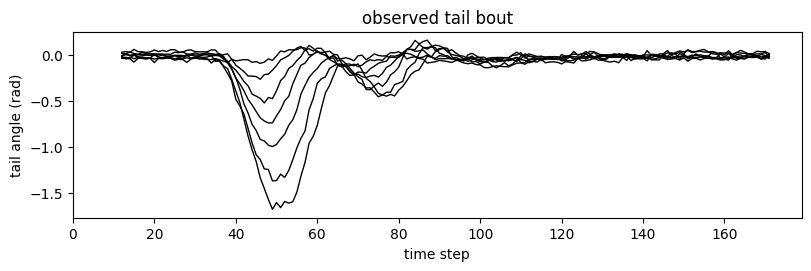

In [4]:
data = dict(onp.load(Path("../../../tests/fixtures/ocaml_mgu.npz")))
p = {k[len("param_"):]: data[k] for k in data if k.startswith("param_")}
TRIAL, N_BEG = 5, 12
obs = data["saved_tail"][TRIAL]  # (160, 7) observed tail
T, m = data["ilqr_u"].shape[1:]
n, n_out = p["uh"].shape[0], p["c"].shape[0]
print(f"T={T}, latents n={n}, inputs m={m}, tail channels={n_out}")

t_obs = onp.arange(obs.shape[0]) + N_BEG
fig, ax = plt.subplots(figsize=(8, 2.6), layout="constrained")
# ax.plot(t_obs, obs + 2.0 * onp.arange(n_out), c="k", lw=1)

_ = ax.plot(t_obs, obs, c="k", lw=1)
_ = ax.set(xlabel="time step", ylabel="tail angle (rad)", title="observed tail bout", xlim=[0,None])

## Defining the model

All parameters go into `theta`, a `NamedTuple` pytree. For $t < n_\text{beg}$ the dynamics load the inputs
into disjoint blocks of the latent state, $x_{t+1} = x_t + B^{(t)\top} u_t$. Afterwards the MGU2 update is

$$
f = \sigma(b_f + U_f^\top x), \qquad h = \tanh\!\big(b_h + U_h^\top (x \odot f)\big) + B^\top u, \qquad
x' = (1 - f) \odot x + f \odot h .
$$

In [5]:
class Theta(NamedTuple):
    B: jnp.ndarray  # (m, n) normalised input weights
    uh: jnp.ndarray  # (n, n)
    uf: jnp.ndarray  # (n, n)
    bh: jnp.ndarray  # (n,)
    bf: jnp.ndarray  # (n,)
    beg_bs: jnp.ndarray  # (n_beg, m, n) initial-condition loadings
    c: jnp.ndarray  # (n_out, n)
    bias: jnp.ndarray  # (n_out,)
    variances: jnp.ndarray  # (n_out,)
    sigma: jnp.ndarray  # (m,) Student-t scale
    sigma0: jnp.ndarray  # (m,) Gaussian scale of the first n_beg inputs
    nu: jnp.ndarray  # () degrees of freedom
    obs: jnp.ndarray  # (T - n_beg + 1, n_out)


k, i, j = onp.meshgrid(onp.arange(N_BEG), onp.arange(m), onp.arange(n), indexing="ij")
theta = Theta(
    B=jnp.sqrt(n / m) * p["wh"] / jnp.linalg.norm(p["wh"], axis=1, keepdims=True),
    uh=jnp.asarray(p["uh"]),
    uf=jnp.asarray(p["uf"]),
    bh=jnp.asarray(p["bh"]),
    bf=jnp.asarray(p["bf"]),
    beg_bs=jnp.asarray(((j // N_BEG == k) & (j % m == i)).astype(float)),
    c=jnp.asarray(p["c"]),
    bias=jnp.asarray(p["bias"]),
    variances=jnp.asarray(p["variances"]),
    sigma=jnp.sqrt((p["nu"] - 2.0) / p["nu"]) * p["spatial_stds"],
    sigma0=jnp.asarray(p["first_step"]),
    nu=jnp.asarray(p["nu"]),
    obs=jnp.asarray(obs),
)


def dynamics(t, x, u, theta):
    def load(_):
        return x + theta.beg_bs[jnp.minimum(t, N_BEG - 1)].T @ u

    def mgu(_):
        f = jax.nn.sigmoid(theta.bf + theta.uf.T @ x)
        h = jnp.tanh(theta.bh + theta.uh.T @ (x * f)) + theta.B.T @ u
        return (1.0 - f) * x + f * h

    return jax.lax.cond(t < N_BEG, load, mgu, None)


def readout(xs, theta):
    return theta.bias + xs @ theta.c.T

## The cost: a sparse prior plus the likelihood

The running cost is the negative log prior of $u_t$, Gaussian for the initial-condition steps and multivariate
Student-$t$ afterwards, plus the Gaussian negative log likelihood of observation $t - n_\text{beg}$ given $x_t$.
There is no terminal cost. The Student-$t$ term is not convex in $u$, so the problem has local optima; iLQR uses
its exact Hessian with Levenberg–Marquardt regularisation.

In [6]:
def prior(t, u, theta):
    gauss = 0.5 * (m * jnp.log(2 * jnp.pi) + 2 * jnp.sum(jnp.log(theta.sigma0)) + jnp.sum((u / theta.sigma0) ** 2))
    nu = theta.nu
    cst = gammaln(0.5 * nu) - gammaln(0.5 * (nu + m)) + 0.5 * m * jnp.log(jnp.pi * nu) + jnp.sum(jnp.log(theta.sigma))
    student = cst + 0.5 * (nu + m) * jnp.log1p(jnp.sum((u / theta.sigma) ** 2) / nu)
    return jnp.where(t < N_BEG, gauss, student)


def likelihood(t, x, theta):
    r = theta.obs[jnp.clip(t - N_BEG, 0, theta.obs.shape[0] - 1)] - (theta.bias + theta.c @ x)
    nll = 0.5 * (n_out * jnp.log(2 * jnp.pi) + jnp.sum(jnp.log(theta.variances)) + jnp.sum(r**2 / theta.variances))
    return jnp.where(t < N_BEG, 0.0, nll)


def cost(t, x, u, theta):
    return prior(t, u, theta) + likelihood(t, x, theta)


def costf(x, theta):
    return jnp.zeros(())


model = System(cost, costf, dynamics, ModelDims(n=n, m=m, horizon=T, dt=1.0))
params = iLQRParams(x0=jnp.zeros(n), theta=theta)

## Solving

Starting from zero inputs, the solver runs until the KKT residual falls below `kkt_tol`. A first trial step of
$\alpha = 1$ (`alpha_init=2.0`) suits this problem better than the cautious default.

In [7]:
Us_zero = jnp.zeros((T, m))
solve = jax.jit(lambda u0: ilqr_solver(model, params, u0, max_iter=1000, alpha_init=2.0, kkt_tol=1e-6))
(Xs, Us, _), J_opt, cost_log = solve(Us_zero)
(X_zero, _), J_zero = ilqr_simulate(model, Us_zero, params)

J_ocaml = data["ilqr_cost"][TRIAL]
print(f"cost: {float(J_zero):.1f} (zero input) -> {float(J_opt):.3f} (diffilqrax), OCaml {J_ocaml:.3f}")
print(f"max |u* - u*_OCaml| = {float(jnp.abs(Us - data['ilqr_u'][TRIAL]).max()):.1e}")

cost: 23917.4 (zero input) -> -10403.917 (diffilqrax), OCaml -10403.917
max |u* - u*_OCaml| = 3.1e-07


For this bout both implementations reach the same optimum. On other bouts they can stop in different local
optima of the non-convex objective, with costs that agree to about $10^{-3}$.

## Reconstruction

With zero input the latents relax to a fixed point and the readout is flat; the inferred inputs reproduce
the bout. The latents saved by the solver are $x_0 \dots x_T$, so observation $j$ is read out from
`Xs[j + N_BEG]`.

R^2 of the reconstruction: 0.993


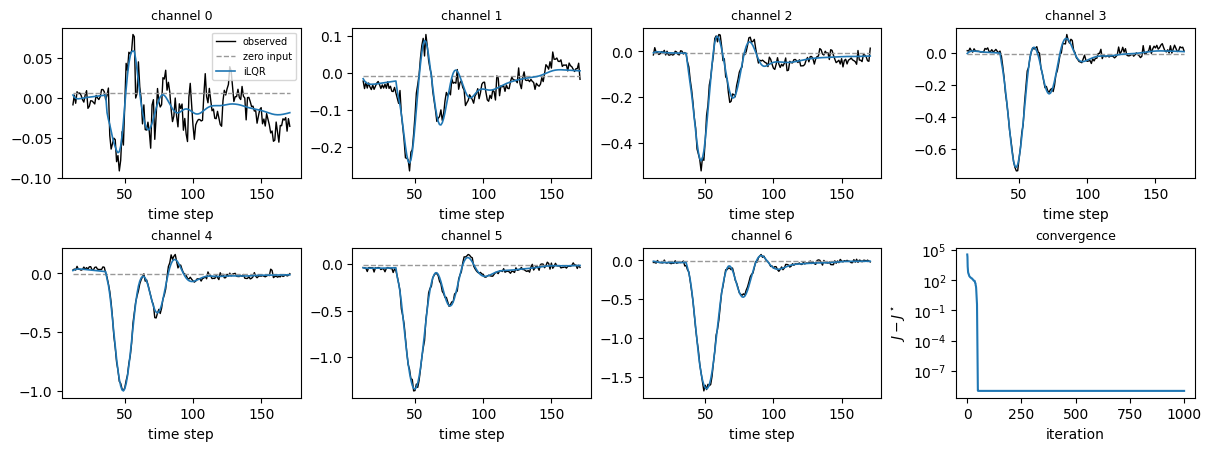

In [8]:
o_zero = readout(X_zero[N_BEG:N_BEG + obs.shape[0]], theta)
o_opt = readout(Xs[N_BEG:N_BEG + obs.shape[0]], theta)
r2 = 1 - jnp.sum((o_opt - obs) ** 2) / jnp.sum((obs - obs.mean(0)) ** 2)
print(f"R^2 of the reconstruction: {float(r2):.3f}")

fig, axes = plt.subplots(2, 4, figsize=(12, 4.4), layout="constrained")
for ch, ax in enumerate(axes.flat[:n_out]):
    ax.plot(t_obs, obs[:, ch], c="k", lw=1, label="observed")
    ax.plot(t_obs, o_zero[:, ch], c="0.6", ls="--", lw=1, label="zero input")
    ax.plot(t_obs, o_opt[:, ch], c="C0", lw=1.2, label="iLQR")
    ax.set_title(f"channel {ch}", fontsize=9)
    ax.set_xlabel("time step")
axes.flat[0].legend(fontsize=7)
ax = axes.flat[-1]
ax.semilogy(cost_log - cost_log.min() + 1e-9, c="C0")
ax.set(xlabel="iteration", ylabel=r"$J - J^\star$", title="convergence")
ax.title.set_fontsize(9);

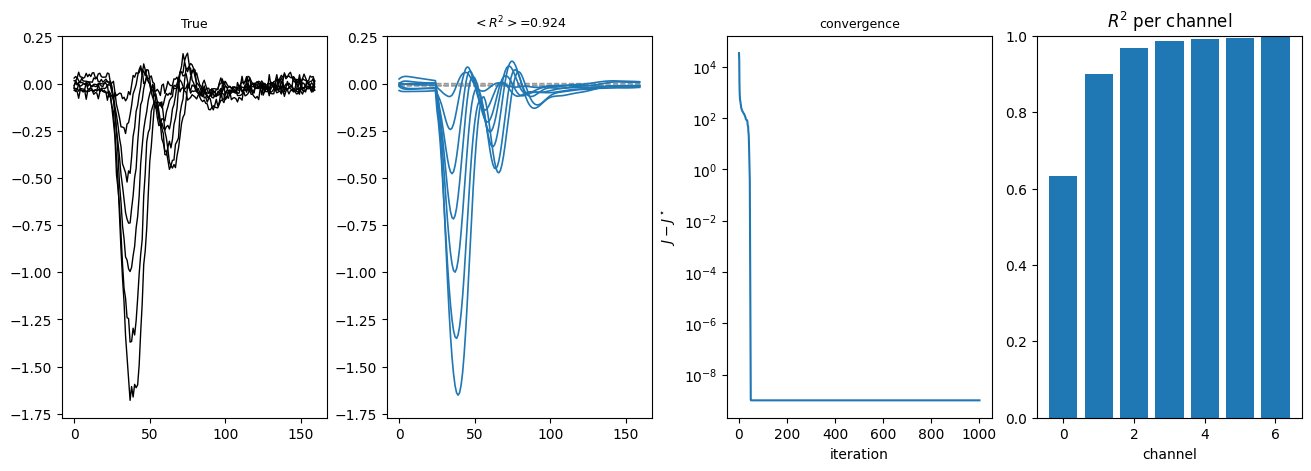

In [15]:
# o_opt = onp.asarray(readout(theta, Xs))[N_BEG - 1 :]
# o_zero = onp.asarray(readout(theta, X_zero))[N_BEG - 1 :]
r2 = 1 - ((o_opt - obs) ** 2).sum(0) / ((obs - obs.mean(0)) ** 2).sum(0)

fig, axes = plt.subplots(1, 4, figsize=(13, 4.6), layout="constrained")
# for ch, ax in enumerate(axes.flat[:n_out]):
# axes[0]
axes[0].plot(obs[:, :], c="k", lw=1, label="observed")
# axes[0].plot(o_zero[:, :], c="0.6", ls="--", lw=1, label="zero input")
# axes[0].plot(o_opt[:, :], c="C0", lw=1.2, label="iLQR")
axes[0].set_title(f"True", fontsize=9)
# axes.flat[0].legend(fontsize=7)
axes[1].plot(o_zero[:, :], c="0.6", ls="--", lw=1, label="zero input")
axes[1].plot(o_opt[:, :], c="C0", lw=1.2, label="iLQR")
axes[1].set_title(f"$<R^2>$={r2.mean(0):.3f}", fontsize=9)

# ax = axes.flat[-2]
axes.flat[-1].bar(range(n_out), r2)
axes.flat[-1].set(ylim=(0, 1), xlabel="channel", title="$R^2$ per channel");

axes[0].sharey(axes[1])
ax = axes.flat[2]
ax.semilogy(cost_log - cost_log.min() + 1e-9, c="C0")
ax.set(xlabel="iteration", ylabel=r"$J - J^\star$", title="convergence")
ax.title.set_fontsize(9);

The inferred inputs are sparse, as the Student-$t$ prior intends: one large kick that launches the bout, a
smaller one a few beats later, and near-zero inputs elsewhere. The latent dynamics generate the undulation
on their own.

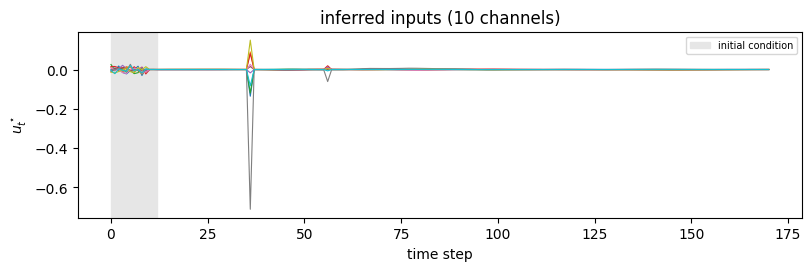

In [7]:
fig, ax = plt.subplots(figsize=(8, 2.6), layout="constrained")
ax.plot(Us, lw=0.8)
ax.axvspan(0, N_BEG, color="0.9", label="initial condition")
ax.set(xlabel="time step", ylabel=r"$u^\star_t$", title="inferred inputs (10 channels)")
ax.legend(fontsize=7);

## How to adapt

- **Another bout**: change `TRIAL`; only `theta.obs` depends on the bout, so `solve` is reused without
  recompiling.
- **Many bouts at once**: `jax.vmap(solve_for_obs)` over the observations, with `obs` passed in `theta`.
- **Learning the model**: the solution is differentiable with respect to `theta`
  (see [gradients through iLQR](gradients_through_ilqr.ipynb)), which is how an iLQR-VAE is trained.
- **A Gaussian prior** makes the cost convex in $u$ for fixed latents and typically converges in fewer
  iterations, at the price of less sparse inputs.